In [1]:
# ============================================================
# GUÍA 4 - PARTE III
# TERMÓMETRO DE REZAGO CATASTRAL
# TÉCNICAS PARA UN PRIMER ENTENDIMIENTO DE LOS DATOS
# Periodo: 2015-2023 | Piloto AMB
# Entradas: salidas de la Parte II (limpieza_amb.py)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture

SEMILLA = 0

# ------------------------------------------------------------
# CARGA Y VALIDACIÓN INICIAL
# ------------------------------------------------------------

archivo_ventas = Path("../../datos/compraventas_limpias.csv")
archivo_pares = Path("../../datos/pares_amb.csv")

# Matrícula y pk se leen como texto para no alterar identificadores.
ventas = pd.read_csv(
    archivo_ventas,
    dtype={"matricula": "string", "pk": "string"}
)
pares = pd.read_csv(
    archivo_pares,
    dtype={"matricula": "string", "pk": "string"}
)

ventas["fecha"] = pd.to_datetime(ventas["fecha"])
pares["fecha"] = pd.to_datetime(pares["fecha"])
pares["fecha_ant"] = pd.to_datetime(pares["fecha_ant"])

print("=" * 65)
print("CARGA DE LAS SALIDAS DE LA PARTE II")
print("=" * 65)
print("Compraventas limpias:", ventas.shape)
print("Pares de ventas repetidas:", pares.shape)

if len(ventas) != 133720:
    print("El número de compraventas difiere de 133.720")

if len(pares) != 14469:
    print("ATENCIÓN: el número de pares difiere de 14.469")

if pares["para_indice"].sum() != 13978:
    print("Los pares para el índice difieren de 13.978")

CARGA DE LAS SALIDAS DE LA PARTE II
Compraventas limpias: (133720, 25)
Pares de ventas repetidas: (14469, 31)


In [2]:
# ------------------------------------------------------------
# TÉCNICA 1. FILTRACIÓN
# No se borra ningún registro: cada análisis declara su
# subconjunto mediante una marca.
# ------------------------------------------------------------

print("=" * 65)
print("TÉCNICA 1. FILTRACIÓN")
print("=" * 65)

resumen_filtros = pd.DataFrame({
    "Subconjunto": [
        "Compraventas limpias",
        "Pares de ventas consecutivas (>= 365 días)",
        "Pares excluidos por cambio físico",
        "Pares excluidos por cambio extremo (5x)",
        "Pares para el índice (para_indice)"
    ],
    "Registros": [
        len(ventas),
        len(pares),
        pares["cambio_fisico"].sum(),
        (pares["cambio_extremo_5x"] & ~pares["cambio_fisico"]).sum(),
        pares["para_indice"].sum()
    ]
})

display(resumen_filtros)

TÉCNICA 1. FILTRACIÓN


,Subconjunto,Registros
0,Compraventas limpias,133720
1,Pares de ventas consecutivas (>= 365 días),14469
2,Pares excluidos por cambio físico,156
3,Pares excluidos por cambio extremo (5x),335
4,Pares para el índice (para_indice),13978


In [3]:
# ------------------------------------------------------------
# TÉCNICA 2. IMPUTACIÓN
# Se verifica que no haya vacíos en los campos del modelo.
# Si no los hay, la técnica no se aplica.
# ------------------------------------------------------------

print("=" * 65)
print("TÉCNICA 2. IMPUTACIÓN")
print("=" * 65)

campos_modelo = [
    "matricula", "fecha", "valor",
    "municipio", "tipo_predio_zona",
    "documento_justificativo"
]

vacios_modelo = (
    ventas[campos_modelo]
    .isna()
    .sum()
    .to_frame("Nulos")
)
vacios_modelo["% Nulos"] = (
    vacios_modelo["Nulos"] / len(ventas) * 100
).round(2)

display(vacios_modelo)

if vacios_modelo["Nulos"].sum() == 0:
    print("No hay vacíos en los campos del modelo: no se imputa.")
    print("Imputar el valor fabricaría el precio que se quiere medir.")

TÉCNICA 2. IMPUTACIÓN


,Nulos,% Nulos
matricula,0,0.0
fecha,0,0.0
valor,0,0.0
municipio,0,0.0
tipo_predio_zona,0,0.0
documento_justificativo,0,0.0


No hay vacíos en los campos del modelo: no se imputa.
Imputar el valor fabricaría el precio que se quiere medir.


In [4]:
# ------------------------------------------------------------
# TÉCNICA 3. REDUCCIÓN DE DIMENSIONES (POR SELECCIÓN)
# Con una sola variable numérica de fondo (valor), un ACP no
# aporta se eliminan columnas constantes, redundantes o
# inconsistentes en el tiempo
# ------------------------------------------------------------

print("=" * 65)
print("TÉCNICA 3. REDUCCIÓN DE DIMENSIONES")
print("=" * 65)

valores_unicos = ventas.nunique()
columnas_constantes = valores_unicos[valores_unicos == 1].index.tolist()

print("Columnas constantes:", columnas_constantes)

print(
    "divipola y municipio son 1 a 1:",
    ventas.groupby("divipola")["municipio"].nunique().max() == 1
)

print("\nORIP POR MUNICIPIO")
display(pd.crosstab(ventas["municipio"], ventas["orip"]))

# Notaría: se intenta extraer del texto del documento
ventas["notaria"] = ventas["documento_justificativo"].str.extract(
    r"NOTARIA\s+([A-Z\u00c0-\u00dc ]+?)\s*-"
)[0]

print("\nNOTARÍA LEGIBLE POR AÑO (%)")
display(
    ventas.groupby("year_radica")["notaria"]
    .apply(lambda s: s.notna().mean() * 100)
    .round(1)
    .to_frame("% legible")
)

columnas_redundantes = [
    "divipola", "orip", "fecha_radica_texto", "year_radica"
]

columnas_salen = columnas_constantes + columnas_redundantes

print(
    f"\nColumnas: {ventas.shape[1] - 1} -> "
    f"{ventas.shape[1] - 1 - len(columnas_salen)} "
    "(sin contar la notaría auxiliar)"
)

TÉCNICA 3. REDUCCIÓN DE DIMENSIONES
Columnas constantes: ['categoria_ruralidad_2024', 'cod_natujur', 'departamento', 'dinamica_2024', 'nombre_natujur', 'tiene_mas_de_un_valor', 'tiene_valor']
divipola y municipio son 1 a 1: True

ORIP POR MUNICIPIO


orip,300,314
municipio,,
BUCARAMANGA,57231,0
FLORIDABLANCA,26089,0
GIRÓN,21131,0
PIEDECUESTA,0,29269



NOTARÍA LEGIBLE POR AÑO (%)


,% legible
year_radica,
2015,100.0
2016,100.0
2017,100.0
2018,100.0
2019,100.0
2020,100.0
2021,45.7
2022,0.0
2023,0.0



Columnas: 25 -> 14 (sin contar la notaría auxiliar)


In [5]:
# ------------------------------------------------------------
# TÉCNICAS 4 Y 6. EXTRACCIÓN DE VARIABLES E INFORMACIÓN EXTERNA
# ------------------------------------------------------------

print("=" * 65)
print("TÉCNICAS 4 Y 6. EXTRACCIÓN DE VARIABLES E INFORMACIÓN EXTERNA")
print("=" * 65)

def fecha_escritura(texto):
    """Lee la fecha de la escritura (dd/mm/aa o dd/mm/aaaa)."""
    d = texto.str.extract(r"(\d{1,2}/\d{1,2}/\d{2,4})")[0]
    larga = pd.to_datetime(d, format="%d/%m/%Y", errors="coerce")
    corta = pd.to_datetime(d, format="%d/%m/%y", errors="coerce")
    return larga.fillna(corta)

# --- Variables a nivel de venta
ventas["log_valor"] = np.log(ventas["valor"])
ventas["redondo"] = ventas["valor"] % 1_000_000 == 0
ventas["fecha_escritura"] = fecha_escritura(ventas["documento_justificativo"])
ventas["dias_esc_rad"] = (
    ventas["fecha"] - ventas["fecha_escritura"]
).dt.days

# --- Fecha de escritura de la primera venta de cada par
primera = ventas[["matricula", "fecha", "fecha_escritura", "valor"]].rename(
    columns={
        "fecha": "fecha_ant",
        "fecha_escritura": "fesc1",
        "valor": "valor_control"
    }
)
pares = pares.merge(primera, on=["matricula", "fecha_ant"], how="left")

if not (pares["valor_control"] == pares["valor_ant"]).all():
    raise ValueError("La primera venta de algún par no coincide.")

pares["fesc2"] = fecha_escritura(pares["documento_justificativo"])

# Si alguna fecha de escritura no se pudo leer, se usa la fecha de
# radicación de esa venta (la mediana entre ambas es de 15 días).
sin_fesc = pares["fesc1"].isna() | pares["fesc2"].isna()
print("Pares con fecha de escritura no legible (se usa radicación):", sin_fesc.sum())
pares["fesc1"] = pares["fesc1"].fillna(pares["fecha_ant"])
pares["fesc2"] = pares["fesc2"].fillna(pares["fecha"])

# Variables a nivel de par
pares["anios"] = (pares["fecha"] - pares["fecha_ant"]).dt.days / 365.25
pares["g"] = pares["razon"] ** (1 / pares["anios"]) - 1
pares["red1"] = pares["valor_ant"] % 1_000_000 == 0
pares["red2"] = pares["valor"] % 1_000_000 == 0
pares["congelado"] = pares["razon"] == 1

# Información externa 1: reajuste anual de avalúos por decreto
# Verificado: 2018, 2019 y 2022 (3%) y 2023 (4,31%).
# Supuesto: 3% en los demás años, por confirmar.
REAJUSTE = {anio: 0.03 for anio in range(2010, 2023)}
REAJUSTE[2023] = 0.0431

def factor_decreto(a1, a2):
    a1, a2 = int(a1), int(a2)
    return np.prod([1 + REAJUSTE.get(a, 0.03) for a in range(a1 + 1, a2 + 1)])

pares["factor_decreto"] = [
    factor_decreto(a, b)
    for a, b in zip(pares["fesc1"].dt.year, pares["fesc2"].dt.year)
]
pares["desv_decreto"] = pares["razon"] / pares["factor_decreto"] - 1
pares["replica_decreto"] = (
    (pares["desv_decreto"].abs() < 0.005) & ~pares["congelado"]
)

# Información externa 2: Ley 1943 de 2018, art. 53 (precio real
# bajo juramento desde 2019)
pares["cruza_ley1943"] = (
    (pares["fesc1"] < "2019-01-01") & (pares["fesc2"] >= "2019-01-01")
)

# Información externa 3: actualización catastral de Bucaramanga
# vigente desde el 1 de enero de 2019
pares["cruza_act_bga"] = (
    pares["cruza_ley1943"] & (pares["municipio"] == "BUCARAMANGA")
)

variables_nuevas = pd.DataFrame({
    "Variable": [
        "log_valor", "redondo", "fecha_escritura", "dias_esc_rad",
        "anios", "g", "congelado", "factor_decreto",
        "replica_decreto", "cruza_ley1943", "cruza_act_bga"
    ],
    "Nivel": ["Venta"] * 4 + ["Par"] * 7
})
display(variables_nuevas)

print(
    "Fecha de escritura legible:",
    f"{ventas['fecha_escritura'].notna().mean():.1%}"
)
print(
    "Días escritura-radicación (mediana / p95):",
    ventas["dias_esc_rad"].median(),
    "/",
    ventas["dias_esc_rad"].quantile(0.95)
)

# Subconjunto de trabajo para el resto del análisis
pi = pares[pares["para_indice"]].copy()

TÉCNICAS 4 Y 6. EXTRACCIÓN DE VARIABLES E INFORMACIÓN EXTERNA


Pares con fecha de escritura no legible (se usa radicación): 1


,Variable,Nivel
0,log_valor,Venta
1,redondo,Venta
2,fecha_escritura,Venta
3,dias_esc_rad,Venta
4,anios,Par
5,g,Par
6,congelado,Par
7,factor_decreto,Par
8,replica_decreto,Par
9,cruza_ley1943,Par


Fecha de escritura legible: 100.0%
Días escritura-radicación (mediana / p95): 15.0 / 77.0


In [6]:
# ------------------------------------------------------------
# TÉCNICA 5. ESTADÍSTICAS DESCRIPTIVAS
# ------------------------------------------------------------

print("=" * 65)
print("TÉCNICA 5. ESTADÍSTICAS DESCRIPTIVAS")
print("=" * 65)

display(
    ventas["valor"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .apply(lambda x: f"{x:,.0f}")
    .to_frame("Valor (COP)")
)

print(
    "Asimetría del valor:", round(ventas["valor"].skew(), 1),
    "| en logaritmo:", round(ventas["log_valor"].skew(), 2)
)

print("\nMEDIANA POR ZONA (COP millones)")
display(
    (ventas.groupby("tipo_predio_zona")["valor"].median() / 1e6)
    .round(1)
    .to_frame("Mediana")
)

print("\nMEDIANA POR AÑO Y MUNICIPIO (COP millones)")
mediana_anio = ventas.pivot_table(
    index="year_radica",
    columns="municipio",
    values="valor",
    aggfunc="median"
) / 1e6
display(mediana_anio.round(1))

print("\n% DE VALORES MÚLTIPLOS EXACTOS DE COP 1 M")
redondez = ventas.pivot_table(
    index="year_radica",
    columns="municipio",
    values="redondo",
    aggfunc="mean"
)
redondez["AMB"] = ventas.groupby("year_radica")["redondo"].mean()
display((redondez * 100).round(1))

print("\nVARIACIÓN ANUAL DE LOS PARES (g)")
display(
    pi["g"]
    .describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95])
    .round(4)
    .to_frame("g")
)

TÉCNICA 5. ESTADÍSTICAS DESCRIPTIVAS


,Valor (COP)
count,"133,720"
mean,"138,011,708"
std,"614,707,098"
min,"1,018,000"
1%,"3,756,000"
5%,"10,000,000"
25%,"48,261,848"
50%,"98,000,000"
75%,"157,656,088"
95%,"352,530,906"


Asimetría del valor: 161.1 | en logaritmo: -0.7

MEDIANA POR ZONA (COP millones)


,Mediana
tipo_predio_zona,
RURAL,70.0
SIN INFORMACION,30.0
URBANO,100.0



MEDIANA POR AÑO Y MUNICIPIO (COP millones)


municipio,BUCARAMANGA,FLORIDABLANCA,GIRÓN,PIEDECUESTA
year_radica,,,,
2015,105.6,87.2,40.0,73.1
2016,90.0,100.0,55.8,77.0
2017,87.3,90.0,57.0,78.0
2018,104.3,96.5,63.9,94.0
2019,128.0,100.0,70.0,94.2
2020,122.0,111.9,75.0,88.8
2021,120.0,114.0,87.6,107.1
2022,130.0,118.4,94.0,106.0
2023,130.0,132.0,108.4,104.4



% DE VALORES MÚLTIPLOS EXACTOS DE COP 1 M


municipio,BUCARAMANGA,FLORIDABLANCA,GIRÓN,PIEDECUESTA,AMB
year_radica,,,,,
2015,52.9,52.1,53.6,37.0,49.9
2016,49.8,52.8,44.4,40.0,48.0
2017,50.2,57.6,50.7,30.0,46.6
2018,57.3,58.3,56.2,32.1,50.7
2019,69.9,76.2,63.1,55.0,66.5
2020,73.0,65.3,68.0,64.6,68.6
2021,74.1,70.5,71.2,59.0,69.7
2022,70.7,75.1,74.3,55.2,68.5
2023,75.4,76.9,80.4,57.1,72.5



VARIACIÓN ANUAL DE LOS PARES (g)


,g
count,13978.0000
mean,0.0895
std,0.2277
min,-0.7446
5%,-0.0886
10%,-0.0067
25%,0.0008
50%,0.0298
75%,0.0972
90%,0.2790


In [7]:
# ------------------------------------------------------------
# TÉCNICA 7. SEGMENTACIÓN DE LOS PARES
# ------------------------------------------------------------

print("=" * 65)
print("TÉCNICA 7. SEGMENTACIÓN")
print("=" * 65)

def segmento(fila):
    if fila["congelado"]:
        return "1 Valor congelado"
    if fila["replica_decreto"]:
        return "2 Réplica del reajuste"
    if fila["g"] < 0:
        return "5 Caída"
    if fila["g"] <= 0.05:
        return "3 Crecimiento bajo (0-5%)"
    return "4 Crecimiento de mercado (>5%)"

pi["segmento"] = pi.apply(segmento, axis=1)
pi["ambos_redondos"] = pi["red1"] & pi["red2"]

tabla_segmentos = pi.groupby("segmento").agg(
    pares=("g", "size"),
    g_mediana=("g", "median"),
    ambos_redondos=("ambos_redondos", "mean")
)
tabla_segmentos["% pares"] = tabla_segmentos["pares"] / len(pi) * 100
display(tabla_segmentos.round(4))

print("\nSEGMENTO POR MUNICIPIO (%)")
display(
    (pd.crosstab(pi["segmento"], pi["municipio"], normalize="columns") * 100)
    .round(1)
)

print("\nSEGMENTO POR ZONA (%)")
display(
    (pd.crosstab(pi["segmento"], pi["tipo_predio_zona"], normalize="columns") * 100)
    .round(1)
)

pi["periodo"] = np.select(
    [pi["fesc1"] >= "2019-01-01", pi["fesc2"] >= "2019-01-01"],
    ["C ambas 2019+", "B cruza 2019"],
    default="A ambas <2019"
)

print("\nSEGMENTO POR PERIODO DE LAS ESCRITURAS (%)")
display(
    (pd.crosstab(pi["segmento"], pi["periodo"], normalize="columns") * 100)
    .round(1)
)
print("Pares por periodo:", pi["periodo"].value_counts().sort_index().to_dict())

TÉCNICA 7. SEGMENTACIÓN


,pares,g_mediana,ambos_redondos,% pares
segmento,,,,
1 Valor congelado,1718,0.0000,0.8539,12.2907
2 Réplica del reajuste,900,0.0295,0.2878,6.4387
3 Crecimiento bajo (0-5%),4710,0.0182,0.4433,33.6958
4 Crecimiento de mercado (>5%),5139,0.1527,0.5643,36.7649
5 Caída,1511,-0.0817,0.4315,10.8098



SEGMENTO POR MUNICIPIO (%)


municipio,BUCARAMANGA,FLORIDABLANCA,GIRÓN,PIEDECUESTA
segmento,,,,
1 Valor congelado,10.5,10.7,19.5,13.0
2 Réplica del reajuste,6.6,6.5,4.7,7.3
3 Crecimiento bajo (0-5%),33.9,34.2,30.1,35.4
4 Crecimiento de mercado (>5%),36.0,38.2,38.9,35.4
5 Caída,13.0,10.4,6.8,8.9



SEGMENTO POR ZONA (%)


tipo_predio_zona,RURAL,SIN INFORMACION,URBANO
segmento,,,
1 Valor congelado,16.0,15.5,11.8
2 Réplica del reajuste,5.6,6.1,6.5
3 Crecimiento bajo (0-5%),29.3,19.3,34.4
4 Crecimiento de mercado (>5%),42.1,56.9,35.9
5 Caída,7.0,2.2,11.4



SEGMENTO POR PERIODO DE LAS ESCRITURAS (%)


periodo,A ambas <2019,B cruza 2019,C ambas 2019+
segmento,,,
1 Valor congelado,18.3,8.3,17.5
2 Réplica del reajuste,13.8,5.1,4.0
3 Crecimiento bajo (0-5%),22.1,38.4,31.1
4 Crecimiento de mercado (>5%),30.3,37.5,40.0
5 Caída,15.5,10.7,7.3


Pares por periodo: {'A ambas <2019': 2589, 'B cruza 2019': 8174, 'C ambas 2019+': 3215}


In [8]:
# ------------------------------------------------------------
# TÉCNICA 9. AGRUPACIÓN (MEZCLA GAUSSIANA)
# Sin etiqueta verdadera de "precio de mercado" no se entrena
# una clasificación supervisada; la mezcla deja ver los grupos.
# ------------------------------------------------------------

print("=" * 65)
print("TÉCNICA 9. AGRUPACIÓN")
print("=" * 65)

x = np.log1p(pi["g"].to_numpy()).reshape(-1, 1)

bic = {}
for k in range(1, 7):
    modelo = GaussianMixture(k, random_state=SEMILLA, n_init=3).fit(x)
    bic[k] = modelo.bic(x)

display(pd.Series(bic, name="BIC").round(0).to_frame())

k_optimo = min(bic, key=bic.get)
gmm = GaussianMixture(k_optimo, random_state=SEMILLA, n_init=3).fit(x)
pi["grupo_gmm"] = gmm.predict(x)

grupos = pd.DataFrame({
    "peso": gmm.weights_,
    "g_media": np.expm1(gmm.means_.ravel()),
    "desv_log": np.sqrt(gmm.covariances_.ravel()),
    "pares": pd.Series(pi["grupo_gmm"]).value_counts().sort_index().to_numpy()
}).sort_values("g_media")
display(grupos.round(4))

print("\nCRUCE GRUPO x SEGMENTO")
display(pd.crosstab(pi["segmento"], pi["grupo_gmm"]))

TÉCNICA 9. AGRUPACIÓN


,BIC
1,-9270.0
2,-25238.0
3,-26916.0
4,-26981.0
5,-27009.0
6,-27024.0


,peso,g_media,desv_log,pares
2,0.0200,-0.3116,0.3085,189
5,0.0725,-0.0810,0.1063,898
0,0.5320,0.0173,0.0194,8217
4,0.2676,0.1120,0.0744,3341
3,0.0801,0.4024,0.1288,1042
1,0.0277,0.9275,0.2421,291



CRUCE GRUPO x SEGMENTO


grupo_gmm,0,1,2,3,4,5
segmento,,,,,,
1 Valor congelado,1718,0,0,0,0,0
2 Réplica del reajuste,897,0,0,0,3,0
3 Crecimiento bajo (0-5%),4710,0,0,0,0,0
4 Crecimiento de mercado (>5%),468,291,0,1042,3338,0
5 Caída,424,0,189,0,0,898


In [9]:
# ------------------------------------------------------------
# TÉCNICA 8. VARIABLES MÁS IMPORTANTES
# Objetivo: crecer más de 5% anual frente a 0-5% anual
# (solo pares que no bajan de precio).
# ------------------------------------------------------------

print("=" * 65)
print("TÉCNICA 8. VARIABLES MÁS IMPORTANTES")
print("=" * 65)

d = pi[pi["g"] >= 0].copy()
y = (d["g"] > 0.05).astype(int)

X = pd.DataFrame({
    "anio_venta_1": d["fesc1"].dt.year,
    "anio_venta_2": d["fesc2"].dt.year,
    "anios_entre_ventas": d["anios"],
    "log_valor_1": np.log(d["valor_ant"]),
    "redondo_1": d["red1"].astype(int),
    "redondo_2": d["red2"].astype(int),
    "cruza_ley1943": d["cruza_ley1943"].astype(int),
    "cruza_act_bga": d["cruza_act_bga"].astype(int),
    "rural": (d["tipo_predio_zona"] == "RURAL").astype(int),
    "num_vendedores": d["count_de"],
    "num_compradores": d["count_a"],
})
for mun in ["BUCARAMANGA", "FLORIDABLANCA", "GIRÓN", "PIEDECUESTA"]:
    X["mun_" + mun[:5]] = (d["municipio"] == mun).astype(int)

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=SEMILLA, stratify=y
)

bosque = RandomForestClassifier(
    n_estimators=400, min_samples_leaf=20,
    random_state=SEMILLA, n_jobs=-1
).fit(X_tr, y_tr)

auc = roc_auc_score(y_te, bosque.predict_proba(X_te)[:, 1])
print("Pares:", len(d), "| % mercado:", round(y.mean() * 100, 1), "| AUC prueba:", round(auc, 3))

perm = permutation_importance(
    bosque, X_te, y_te, scoring="roc_auc",
    n_repeats=10, random_state=SEMILLA, n_jobs=-1
)
importancia = pd.Series(
    perm.importances_mean, index=X.columns
).sort_values(ascending=False)
display(importancia.round(4).to_frame("Caída del AUC"))

print("\n% MERCADO POR QUINTIL DEL VALOR DE LA PRIMERA VENTA")
d["quintil_valor_1"] = pd.qcut(np.log(d["valor_ant"]), 5, labels=False) + 1
display(
    d.groupby("quintil_valor_1").agg(
        mediana_valor_1_M=("valor_ant", lambda s: s.median() / 1e6),
        pct_mercado=("g", lambda s: (s > 0.05).mean() * 100)
    ).round(1)
)

print("\n% MERCADO SEGÚN REDONDEZ DE LOS DOS VALORES")
display(
    d.assign(mercado=y)
    .groupby(["red1", "red2"])["mercado"]
    .agg(["size", "mean"])
    .round(3)
)

TÉCNICA 8. VARIABLES MÁS IMPORTANTES


Pares: 12467 | % mercado: 41.3 | AUC prueba: 0.676


,Caída del AUC
log_valor_1,0.1129
redondo_2,0.0289
anios_entre_ventas,0.0242
redondo_1,0.0130
anio_venta_2,0.0106
cruza_ley1943,0.0055
mun_FLORI,0.0024
mun_BUCAR,0.0021
cruza_act_bga,0.0019
mun_GIRÓN,0.0019



% MERCADO POR QUINTIL DEL VALOR DE LA PRIMERA VENTA


,mediana_valor_1_M,pct_mercado
quintil_valor_1,,
1,16.3,56.3
2,42.1,48.1
3,71.1,40.1
4,118.0,34.6
5,208.2,26.3



% MERCADO SEGÚN REDONDEZ DE LOS DOS VALORES


size   mean
red1  red2              
False False  1138  0.226
      True   3848  0.423
True  False   767  0.477
      True   6714  0.432

In [10]:
# ------------------------------------------------------------
# ÍNDICE EXPLORATORIO DE VENTAS REPETIDAS (BAILEY-MUTH-NOURSE)
# Anual, base 2015 = 100, comparado con el reajuste por decreto.
# ------------------------------------------------------------

print("=" * 65)
print("ÍNDICE EXPLORATORIO DE VENTAS REPETIDAS")
print("=" * 65)

ANIOS = list(range(2016, 2024))

def indice_bmn(df):
    A = np.zeros((len(df), len(ANIOS)))
    a1 = df["fecha_ant"].dt.year.to_numpy()
    a2 = df["fecha"].dt.year.to_numpy()
    for j, anio in enumerate(ANIOS):
        A[:, j] = (a2 == anio).astype(float) - (a1 == anio).astype(float)
    beta = np.linalg.lstsq(A, np.log(df["razon"].to_numpy()), rcond=None)[0]
    return pd.Series(np.r_[100, 100 * np.exp(beta)], index=[2015] + ANIOS)

indice = pd.DataFrame({
    "Todos los pares": indice_bmn(pi),
    "Ambos valores redondos": indice_bmn(pi[pi["ambos_redondos"]]),
    "Algún valor no redondo": indice_bmn(pi[~pi["ambos_redondos"]]),
})
indice["Avalúo con reajuste por decreto"] = [
    100 * np.prod([1 + REAJUSTE[a] for a in range(2016, t + 1)])
    for t in indice.index
]
display(indice.round(1))

def tasa(serie, a, b):
    return ((serie[b] / serie[a]) ** (1 / (b - a)) - 1) * 100

tramos = pd.DataFrame({
    tramo: [tasa(indice[c], a, b) for c in indice.columns]
    for tramo, (a, b) in {
        "2015-2018": (2015, 2018),
        "2018-2019": (2018, 2019),
        "2019-2023": (2019, 2023),
        "2015-2023": (2015, 2023),
    }.items()
}, index=indice.columns).T
print("\nCRECIMIENTO ANUAL POR TRAMO (%)")
display(tramos.round(2))

print("\nÍNDICE POR MUNICIPIO")
indice_mun = pd.DataFrame({
    mun: indice_bmn(g) for mun, g in pi.groupby("municipio")
})
display(indice_mun.round(1))
print(
    "Salto 2018-2019 (%):",
    ((indice_mun.loc[2019] / indice_mun.loc[2018] - 1) * 100).round(1).to_dict()
)

ÍNDICE EXPLORATORIO DE VENTAS REPETIDAS


,Todos los pares,Ambos valores redondos,Algún valor no redondo,Avalúo con reajuste por decreto
2015,100.0,100.0,100.0,100.0
2016,103.3,104.0,102.8,103.0
2017,105.1,105.9,104.7,106.1
2018,108.5,111.6,106.4,109.3
2019,123.6,127.7,120.8,112.6
2020,125.5,129.9,122.5,115.9
2021,129.7,134.1,126.8,119.4
2022,138.2,144.4,132.9,123.0
2023,143.2,151.3,135.4,128.3



CRECIMIENTO ANUAL POR TRAMO (%)


,Todos los pares,Ambos valores redondos,Algún valor no redondo,Avalúo con reajuste por decreto
2015-2018,2.77,3.72,2.08,3.00
2018-2019,13.88,14.43,13.57,3.00
2019-2023,3.74,4.33,2.90,3.33
2015-2023,4.59,5.31,3.86,3.16



ÍNDICE POR MUNICIPIO


,BUCARAMANGA,FLORIDABLANCA,GIRÓN,PIEDECUESTA
2015,100.0,100.0,100.0,100.0
2016,102.3,108.0,106.7,98.8
2017,102.6,108.8,107.3,106.1
2018,105.6,111.3,115.1,109.2
2019,121.3,131.6,127.1,120.5
2020,121.1,132.3,135.3,123.2
2021,122.6,135.9,147.3,129.4
2022,134.0,143.1,149.5,137.4
2023,138.1,151.2,156.3,140.2


Salto 2018-2019 (%): {'BUCARAMANGA': 14.9, 'FLORIDABLANCA': 18.2, 'GIRÓN': 10.4, 'PIEDECUESTA': 10.3}


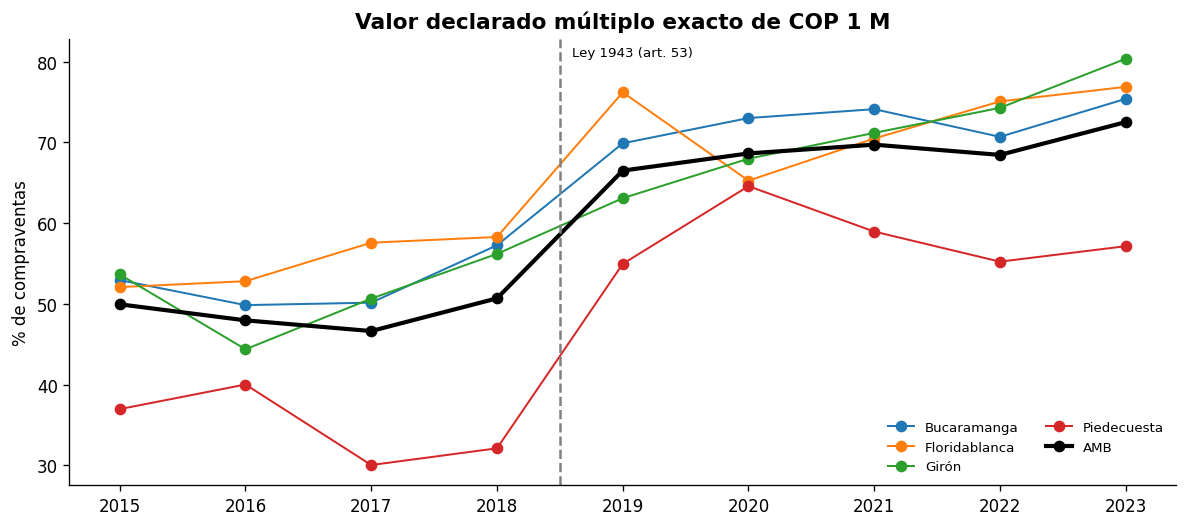

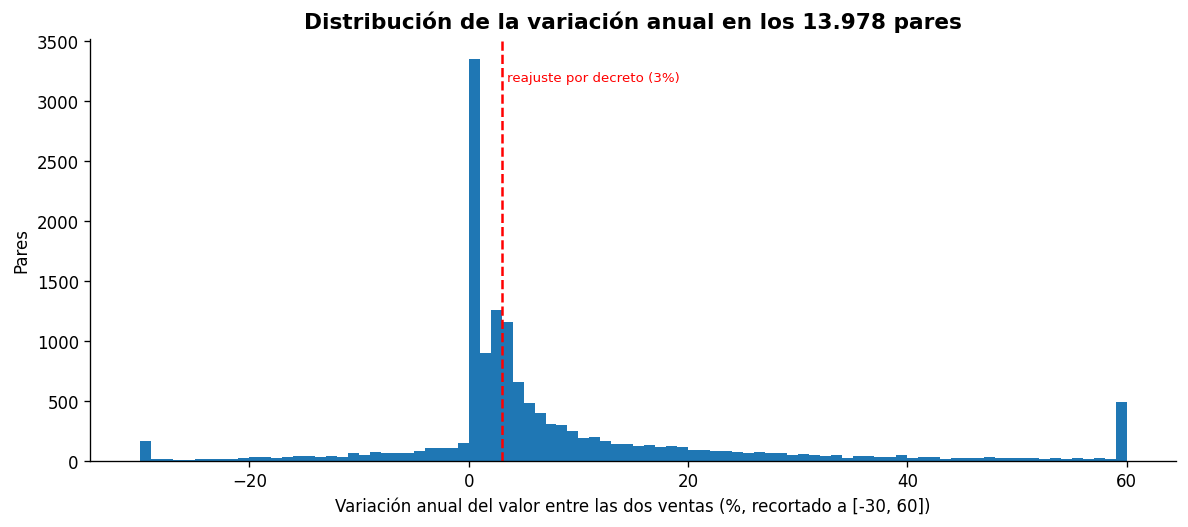

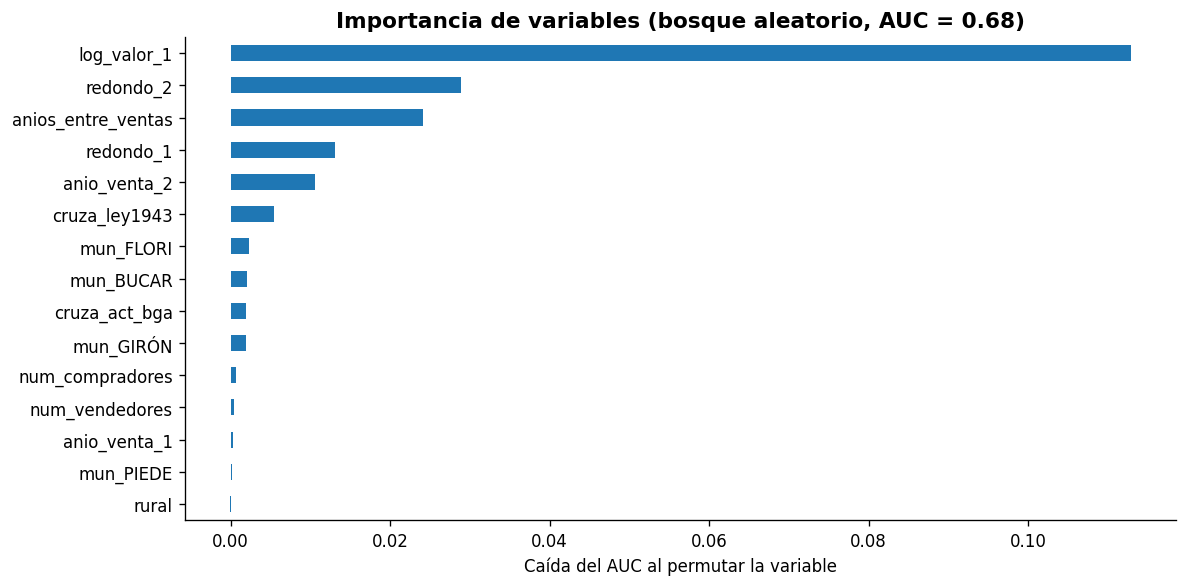

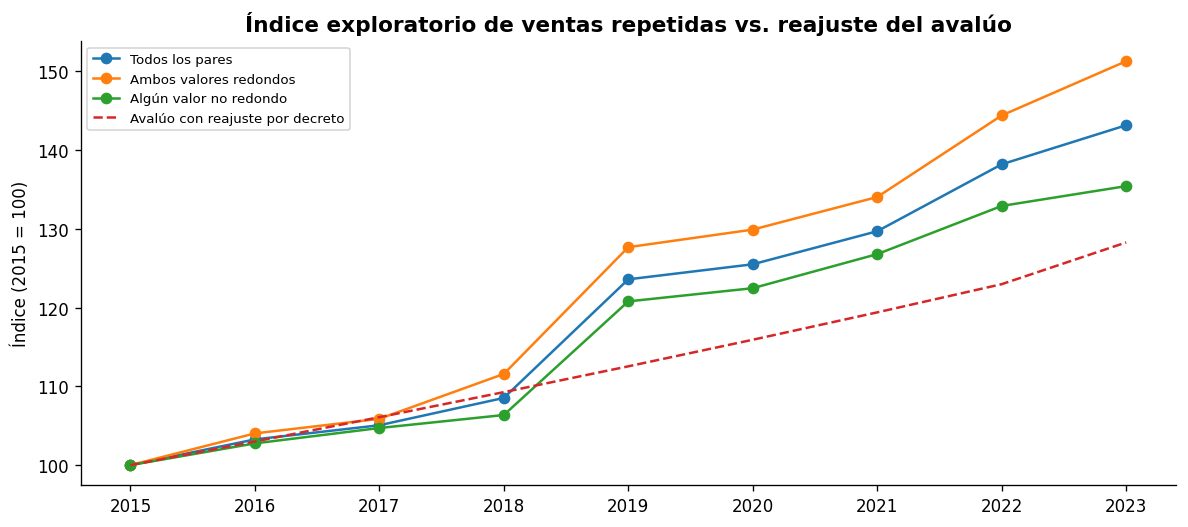

In [11]:
# ============================================================
# GRÁFICAS - PARTE III
# ============================================================

carpeta = Path("../../figuras/guia_4")
carpeta.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 13
})

# ------------------------------------------------------------
# FIGURA 1. REDONDEZ DEL VALOR DECLARADO
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 4.5))
for col in ["BUCARAMANGA", "FLORIDABLANCA", "GIRÓN", "PIEDECUESTA", "AMB"]:
    ax.plot(
        redondez.index, redondez[col] * 100, marker="o",
        lw=2.5 if col == "AMB" else 1.2,
        color="black" if col == "AMB" else None,
        label=col if col == "AMB" else col.title()
    )
ax.axvline(2018.5, ls="--", c="grey")
ax.text(2018.6, 82, "Ley 1943 (art. 53)", fontsize=8, va="top")
ax.set_title("Valor declarado múltiplo exacto de COP 1 M", fontweight="bold")
ax.set_ylabel("% de compraventas")
ax.legend(fontsize=8, ncol=2, loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(carpeta / "fig1_redondez.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# FIGURA 2. DISTRIBUCIÓN DE LA VARIACIÓN ANUAL DE LOS PARES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(pi["g"].clip(-0.3, 0.6) * 100, bins=np.arange(-30, 61, 1))
ax.axvline(3, c="red", ls="--")
ax.text(3.5, ax.get_ylim()[1] * 0.9, "reajuste por decreto (3%)", color="red", fontsize=8)
ax.set_title(f"Distribución de la variación anual en los {len(pi):,} pares".replace(",", "."), fontweight="bold")
ax.set_xlabel("Variación anual del valor entre las dos ventas (%, recortado a [-30, 60])")
ax.set_ylabel("Pares")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(carpeta / "fig2_hist_g.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# FIGURA 3. IMPORTANCIA DE VARIABLES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))
importancia.iloc[::-1].plot.barh(ax=ax)
ax.set_title(f"Importancia de variables (bosque aleatorio, AUC = {auc:.2f})", fontweight="bold")
ax.set_xlabel("Caída del AUC al permutar la variable")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(carpeta / "fig3_importancia.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# FIGURA 4. ÍNDICE EXPLORATORIO FRENTE AL DECRETO
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 4.5))
for col in indice.columns:
    ax.plot(
        indice.index, indice[col],
        ls="--" if "decreto" in col else "-",
        marker=None if "decreto" in col else "o",
        label=col
    )
ax.set_title("Índice exploratorio de ventas repetidas vs. reajuste del avalúo", fontweight="bold")
ax.set_ylabel("Índice (2015 = 100)")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(carpeta / "fig4_indice.png", bbox_inches="tight")
plt.show()